# U-Net: Image Colorization Baseline

We use U-Net to predict the **ab color channels** from the **L (lightness) channel** in Lab color space.

The model was trained using **L1 Loss** for 20 epochs, followed by an additional 20 epochs resumed from the saved model and optimizer states.

This notebook analyzes the results of the trained model without running additional training.

## 1. Experiment Setup

U-Net takes an input tensor **L** of shape `(B, 1, 128, 128)` and predicts **ab** channels of shape `(B, 2, 128, 128)`.

The model was trained with the following configuration:

| Parameter | Value |
|---|---|
| Model | U-Net, `base_channels=32` |
| Loss Function | L1 Loss |
| Optimizer | AdamW |
| Learning Rate | `1e-3` |
| Batch Size | 32 |
| Image Size | 128 × 128 |
| Training | 20 epochs + 20 additional epochs |

The experiment uses the same PASCAL VOC 2012 train/validation/test split defined in the data exploration notebook.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch import nn
from skimage.color import lab2rgb

from image_colorization.unet import UNet
from image_colorization.dataset import ColorizationDataset
from image_colorization.color_utils import denormalize_lab
from torch.utils.data import DataLoader
from torchvision import transforms

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "VOCdevkit" / "VOC2012" / "JPEGImages").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found. Check the VOC2012 dataset directory.")

PACKAGE_ROOT = PROJECT_ROOT / "src" if (PROJECT_ROOT / "src" / "image_colorization").is_dir() else PROJECT_ROOT
if str(PACKAGE_ROOT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_ROOT))


IMAGES_DIR = PROJECT_ROOT / "VOCdevkit" / "VOC2012" / "JPEGImages"
VAL_PATH = PROJECT_ROOT / "data" / "splits" / "val.txt"
CHECKPOINT_PATH = PROJECT_ROOT / "checkpoints" / "unet_baseline_v1_40ep_best.pt"

BATCH_SIZE = 32
IMAGE_SIZE = 128
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
val_transform = transforms.Compose([transforms.Resize(IMAGE_SIZE), transforms.CenterCrop(IMAGE_SIZE)])
val_dataset = ColorizationDataset(IMAGES_DIR, VAL_PATH, transform=val_transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Validation images:", len(val_dataset))
print("Device:", device)

Validation images: 2569
Device: cpu


## 2. Training History

The U-Net was initially trained for 20 epochs. Since both training and validation losses continued to decrease, training was extended for another 20 epochs using the saved model weights and AdamW optimizer state.

The following plots show two training runs logged in **Weights & Biases (W&B)**. In the second run, the `Step` counter starts from zero again, but it represents epochs 21–40 rather than a new training process.

[Initial Training Run](https://wandb.ai/arzushkaB/image-colorization/runs/ngviphfh) · [W&B Project](https://wandb.ai/arzushkaB/image-colorization)


**First 20 Epochs:**

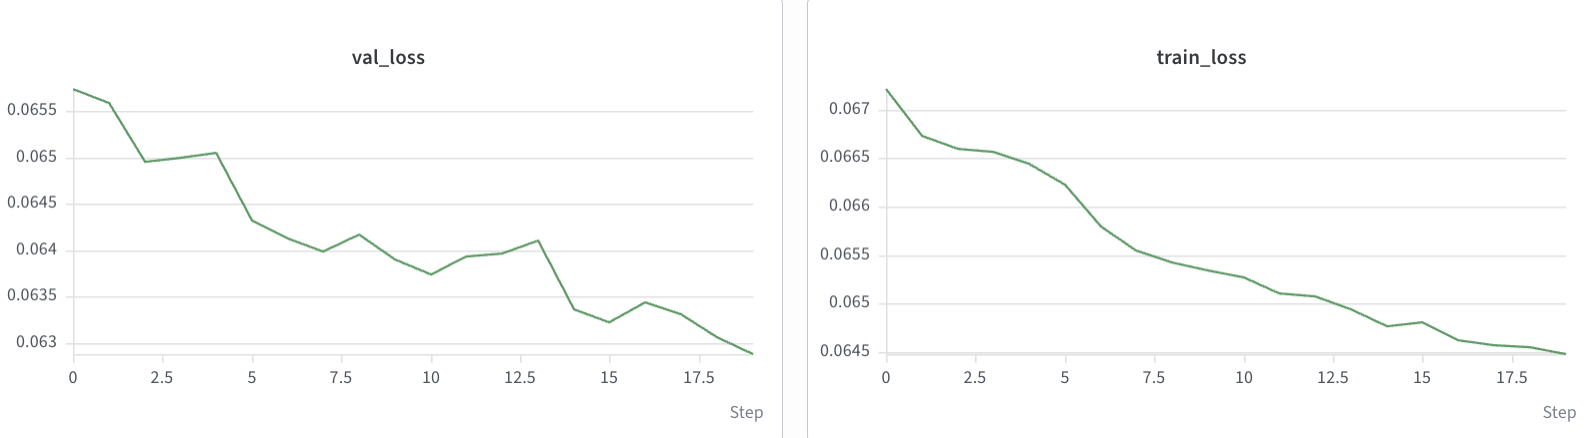

**Training Continuation — Additional 20 Epochs:**

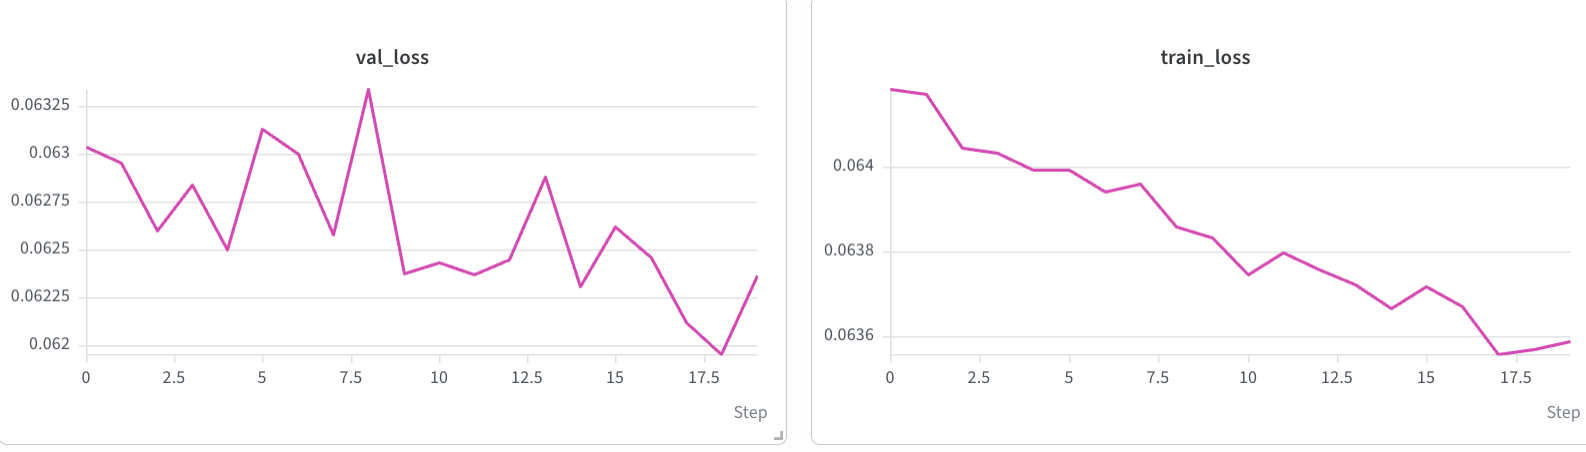

At the end of the first training stage, the train loss was **0.06448**, and the validation loss was **0.06289**. During the second stage, both losses decreased slightly, but the improvements became less significant.

## 3. Loading the Trained Model

We load the checkpoint with the lowest validation loss after 40 epochs of training.

The model code is stored in the repository, while the trained weights are stored locally in the `checkpoints/` directory.

In [ ]:
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model = UNet(in_channels=1, out_channels=2, base_channels=32).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])

Checkpoint epoch: 39


The dashed line marks the transition between the initial 20 epochs and the additional training stage.

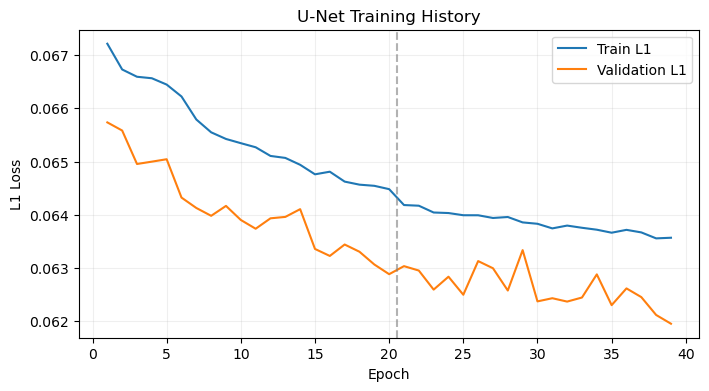

In [ ]:
train_losses = checkpoint.get("train_losses", [])
val_losses = checkpoint.get("val_losses", [])

if train_losses and val_losses:
    epochs = range(1, len(train_losses) + 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, train_losses, label="Train L1")
    ax.plot(epochs, val_losses, label="Validation L1")
    if len(train_losses) > 20:
        ax.axvline(20.5, linestyle="--", color="gray", alpha=0.6)
    ax.set(xlabel="Epoch", ylabel="L1 Loss", title="U-Net Training History")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

## 4. Model Evaluation

We evaluate the trained U-Net against a simple grayscale baseline that predicts zero values for both ab channels at every pixel.

L1 loss is calculated on the first validation batch of 32 images, as in the original experiment. These results do not represent performance on the entire validation set.


In [ ]:
L, ab = next(iter(val_loader))
with torch.inference_mode():
    pred_ab = model(L.to(device)).cpu()

criterion = nn.L1Loss()
gray_ab = torch.zeros_like(ab)
print("Gray baseline L1:", criterion(gray_ab, ab).item())
print("UNet L1:", criterion(pred_ab, ab).item())

Gray baseline L1: 0.06416293978691101
UNet L1: 0.06227351352572441


The original experiment produced the following results on the same validation batch:

| Model | L1 Loss |
|---|---:|
| Grayscale baseline (`ab = 0`) | 0.06416 |
| U-Net after 20 epochs | 0.06259 |
| U-Net after 40 epochs | 0.06227 |

Extending training from 20 to 40 epochs slightly reduced the L1 loss. However, the improvement over the grayscale baseline remained relatively small, suggesting that the model struggled to predict sufficiently accurate color information.


## 5. Colorization Examples

We compare the original RGB image, the input lightness channel L, and the RGB image reconstructed using the ab channels predicted by U-Net.

**Predictions after the first 20 epochs:**




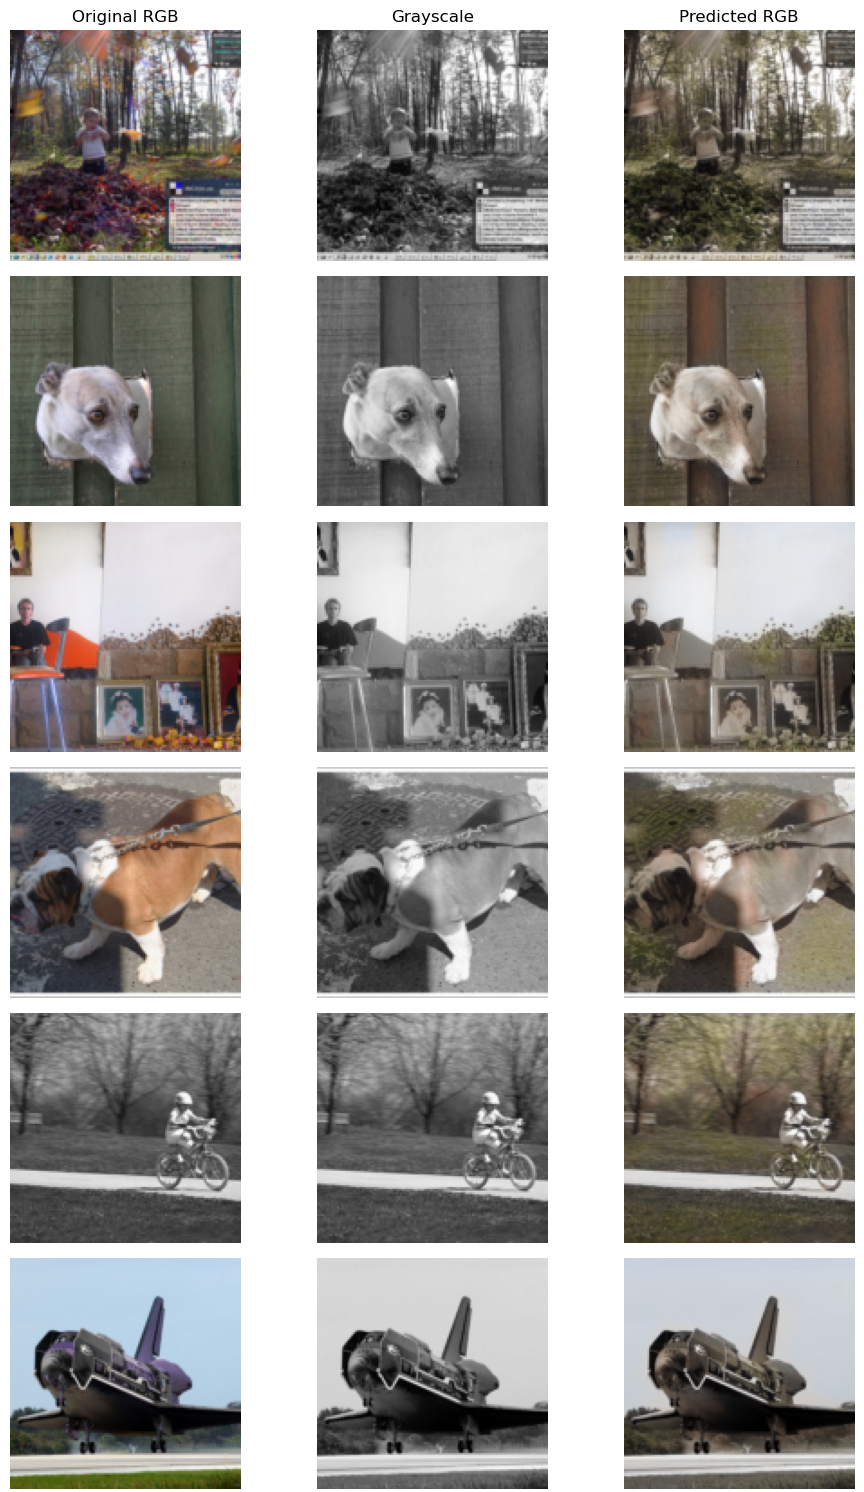

**Predictions after Training Continuation (40 Epochs):**

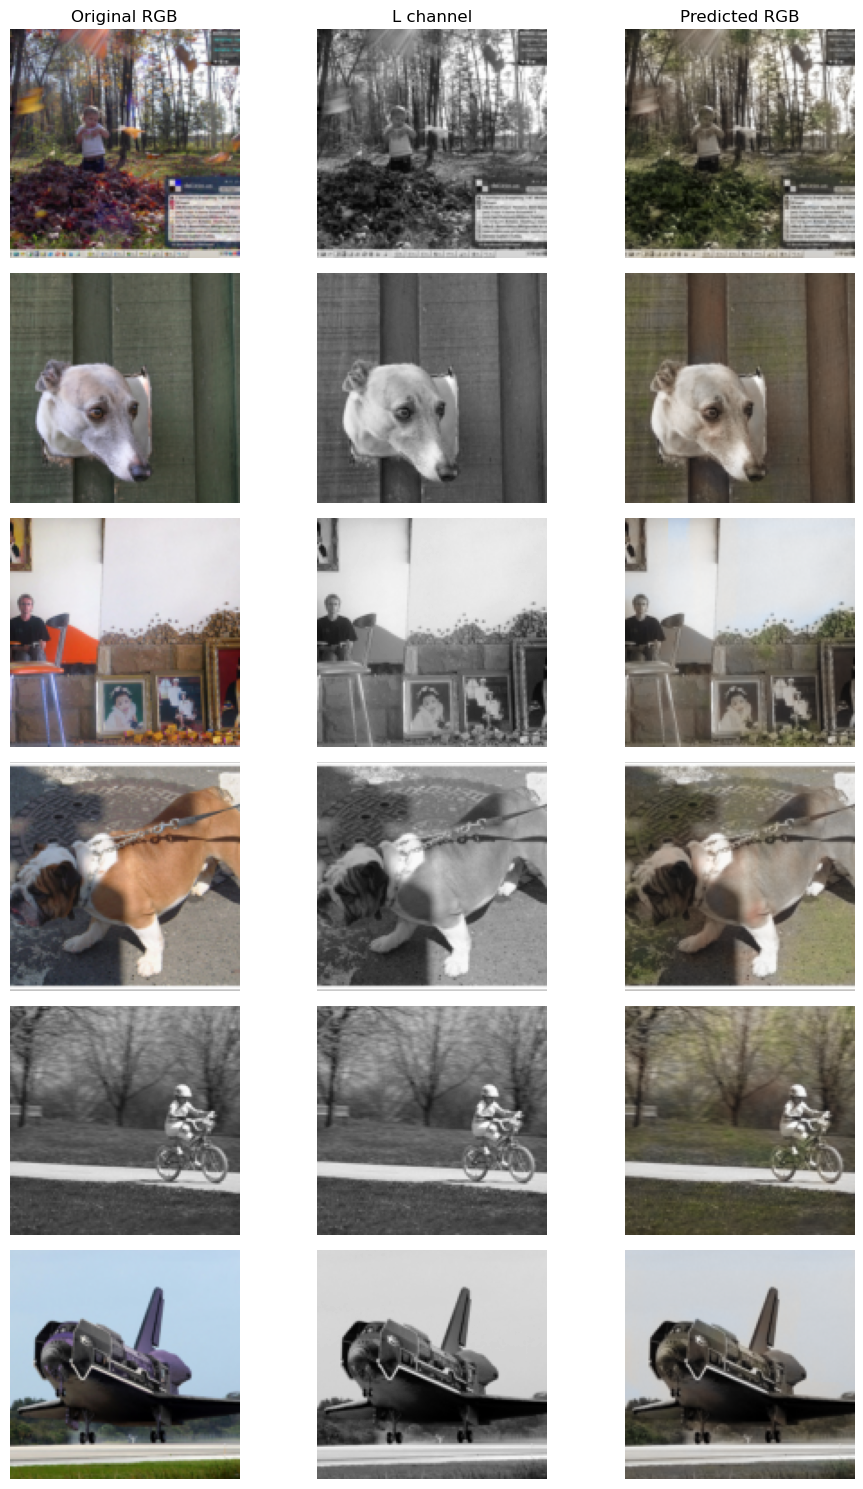

In [ ]:
n_show = min(6, len(L))
fig, axes = plt.subplots(n_show, 3, figsize=(10, n_show * 2.5), squeeze=False)

for i in range(n_show):
    lightness = L[i, 0].numpy()
    true_ab = ab[i].permute(1, 2, 0).numpy()
    predicted_ab = pred_ab[i].permute(1, 2, 0).numpy()

    axes[i, 0].imshow(np.clip(lab2rgb(denormalize_lab(lightness, true_ab)), 0, 1))
    axes[i, 1].imshow(lightness, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(np.clip(lab2rgb(denormalize_lab(lightness, predicted_ab)), 0, 1))
    for ax in axes[i]:
        ax.axis("off")

axes[0, 0].set_title("Original RGB")
axes[0, 1].set_title("L channel")
axes[0, 2].set_title("Predicted RGB")
plt.tight_layout()
plt.show()

### Color Channel Analysis

We compare the mean absolute values of the ground-truth and predicted a and b channels.

Smaller absolute values indicate that the predicted colors are closer to neutral tones in Lab color space.


In [ ]:
for group, x in [("True", ab), ("Pred", pred_ab)]:
    print(group)
    print("Mean |a|:", x[:, 0].abs().mean().item())
    print("Mean |b|:", x[:, 1].abs().mean().item())

True
Mean |a|: 0.04467958211898804
Mean |b|: 0.08364629745483398
Pred
Mean |a|: 0.01101844385266304
Mean |b|: 0.04666456580162048


## 6. Conclusions

U-Net learned to partially reconstruct colors, but the predictions remained mostly desaturated. Training for an additional 20 epochs slightly reduced the L1 loss, while the predicted a and b values remained significantly smaller than the ground truth.

One possible explanation is the regression loss function, which may favor more neutral colors when multiple colorizations are plausible. However, model architecture, dataset size, and training configuration may also affect the results.

In the following experiments, we will explore color classification methods proposed in *Colorful Image Colorization* and compare them with the regression-based baseline.
